# **Assignment 1**

 In this assignment you are going to learn how to build a CNN model, train it and test it. This is fundamental for your upcoming assignments. This first assignment is for getting started purposes. It will not be required for you to provide a report.

**Contents:**
*   Build a CNN
*   Load and prepare a Dataset
*   Training a model
*   Testing a model

In case of implementation doubts, check the PyTorch documentation (https://pytorch.org/docs/stable/nn.html)












# **Tutorial**
Let's start by importing the torch libray.

In [1]:
# Library imports
import torch
import torch.nn as nn
import torch.nn.functional as F

###**Build a CNN model**

**Essential building blocks for a CNN model:**
### 1.  Convolutional layer -> nn.Conv2d
Parameters:
*   in_channels (int) – Number of channels in the input image
*   out_channels (int) – Number of channels produced by the convolution
*   kernel_size (int or tuple) – Size of the convolving kernel
*   stride (int or tuple, optional) – Stride of the convolution. Default: 1
*   padding (int, tuple or str, optional) – Padding added to all four sides of the input. Default: 0

(https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)

Example: nn.Conv2d(in_channels=3, out_channels=32, kernel_size=(3,4), stride=3, padding=2)
### 2.  Fully Connected layer -> nn.Linear
Parameters:
*   in_features – size of each input sample
*   out_features – size of each output sample

(https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)

Example: nn.Linear(in_features=512, out_features=256)

### 3.  Dropout -> nn.Dropout
*   p – probability of an element to be zeroed. Default: 0.5

(https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html)

Example: nn.Dropout(p=0.5)


In [2]:
# Let's build your first CNN model

class nnModel(nn.Module):
  def __init__(self, number_of_classes=1):
    super(nnModel, self).__init__() # NN Module Initialization
    # 1st Convolutional layer
    self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, stride=1, padding=1)
    # Linear layer
    self.fc1 = nn.Linear(in_features=8*28*28, out_features=number_of_classes) # Last layer's output must be the same as the number of classes/categories

    # Dropout
    self.dropout = nn.Dropout(p=0.15)

  def forward(self, x):
    # In "forward" function, you define the behaviour of your CNN
    # Activation functions are also implemented in "forward" function
    # Convolutional layer
    x = F.relu(self.conv1(x))
    # Before passing features to the linear layers, you need to "flatten" the features.
    flat_x = x.view(x.shape[0], -1)

    #Fully Connected layer (Linear layer)
    flat_x = self.fc1(flat_x)
    #flat_x = self.dropout(flat_x) # You can use dropout wherever you "want"


    return flat_x




###**Initializing the network:**
*   Assign the CNN model to the GPU (if available)
*   Check the CNN architecure using torchsummary (important to check if the layers' input and output dimensions are correctly set)


In [3]:
# Check your built CNN model
cnn_model = nnModel(10)
print("CNN Architecture: "+ str(cnn_model))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('\nThe model will run on', device)
cnn_model = cnn_model.to(device)

# Using the torchsummary, you can check your network in more detail
import torchsummary
print("\n\n")
torchsummary.summary(cnn_model, input_size = (1, 28, 28), batch_size = 5)



CNN Architecture: nnModel(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=6272, out_features=10, bias=True)
  (dropout): Dropout(p=0.15, inplace=False)
)

The model will run on cuda



----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1             [5, 8, 28, 28]              80
            Linear-2                    [5, 10]          62,730
Total params: 62,810
Trainable params: 62,810
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.24
Params size (MB): 0.24
Estimated Total Size (MB): 0.49
----------------------------------------------------------------


## **Dataset**

####**Dataset**
MNIST database - a set of 70,000 28×28 pixel grayscale images of handwritten digits (a training set with 60,000 examples, and a test set with 10,000 examples)

**Goal:** Classify images of handwritten digits into one of 10 classes representing the values from 0 to 9.



In [4]:
# Library imports
import numpy as np
import torchvision
from torchvision import datasets # Datasets module
import torchvision.transforms as transforms # Image Transforms
from torch.utils.data.sampler import SubsetRandomSampler # Sampler

In [5]:
# Download the dataset online available on PyTorch
transform = transforms.ToTensor()

training_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
testing_data  = datasets.MNIST(root='data', train=False, download=True, transform=transform)

# Dataset is already divided in training and testing.
# However, to analize the model over the training step, and also perform cross-validation, the training set must be divided in two parts:
#   Training Set (80%)
#   Validation Set (20%)

# Lets start to obtain training indices
num_train = len(training_data)
print("Number of images in original training set: " + str(num_train)) # 60 000
indices = list(range(num_train))

# Randomly Shuffle
np.random.shuffle(indices)

# Split 80%/20%
split = int(np.floor(num_train * 0.2)) # 12 000
print("Split Number: " + str(split))
training_idx, valid_idx = indices[split:], indices[:split] # 48 000 / 12 000
print("Number of training images: " + str(len(training_idx)))
print("Number of validation images: " + str(len(valid_idx)))

# Lets also see how many images are on testing set
print("Number of images in the testing set: " + str(len(testing_data))) # 10 000

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.87MB/s]

Number of images in original training set: 60000
Split Number: 12000
Number of training images: 48000
Number of validation images: 12000
Number of images in the testing set: 10000


In [6]:
# To train the network, you must "encode" the data into a PyTorch dataloader
# Since you divided the original training set in 2, now you need to assign the indices to the samples
training_sampler = SubsetRandomSampler(training_idx)
valid_sampler = SubsetRandomSampler(valid_idx)

batch_size = 16 # 16 images per batch

# Training Set
training_loader = torch.utils.data.DataLoader(dataset = training_data, \
                                              batch_size = batch_size, \
                                              sampler = training_sampler)

# Validation Set
valid_loader = torch.utils.data.DataLoader(dataset = training_data, \
                                           batch_size = batch_size, \
                                           sampler = valid_sampler)

# Testing Set
# Here, you do not need the "sampler" input, since you did not change the original testing set
testing_loader = torch.utils.data.DataLoader(dataset = testing_data, \
                                           batch_size = batch_size, \
                                           shuffle = True)


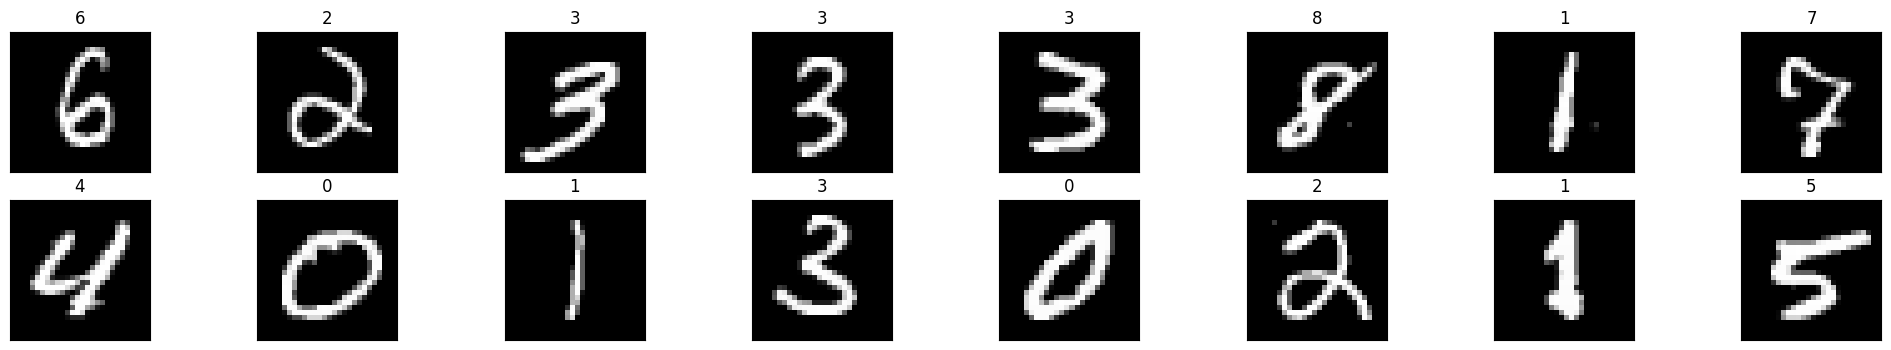

In [7]:
# Visualization of a whole batch
import matplotlib.pyplot as plt

# Get images
dataiter = iter(training_loader)
images, labels = next(dataiter) # Get the images and their labels

# Plot the whole batch
fig = plt.figure(figsize=(25, 4))
# Loop over all the images in the batch(16)
for idx in np.arange(batch_size):
    # Add a subplot for the image
    ax = fig.add_subplot(2, int(batch_size/2), idx+1, xticks=[], yticks=[])
    # Subplot with the image
    ax.imshow(np.squeeze(images[idx]), cmap='gray')
    # print out the correct label for each image
    # .item() gets the value contained in a Tensor
    ax.set_title(str(labels[idx].item()))

## **Training**

**Steps before training the CNN:**

*   Define the loss function
*   Define the optimization/propagation algorithm
*   Define the hyperparameter values (e.g., learning rate, epochs, batch size)
*   Define the evaluation metrics to assess performance in the training dataset

The loss plays an important role in assessing the performance of the CNN model. By analyzing the loss, the model can be said to be learning correctly, to be overfitting or to be underfitting.





In [8]:
# Library imports
import torch.optim as optim

In [11]:
# To train a CNN, you must choose (or develop) a loss function, an optimizer algorithm, and a set of hyper-parameters (learning rate, number of epochs, etc)
# Hyper-parameters
lr = 0.01
num_epochs = 2

# Loss Function
criterion = nn.CrossEntropyLoss() # Cross entropy loss function is widely used in classification problems
# Optimizer Algorithm
optimizer = optim.Adam(cnn_model.parameters(), lr = lr)

# Training
running_loss = 0.0

for epoch in range(num_epochs):
  for batch_id, data in enumerate(training_loader, 0):
    # Get the images and their labels
    images, labels = data
    # Send the images and their labels to the training device
    images, labels = images.to(device), labels.to(device)

    # Pass images through the CNN
    outputs = cnn_model(images)

    # Create a loss value
    loss = criterion(outputs, labels)

    # Backpropagation
    optimizer.zero_grad() # zero the parameter gradients
    loss.backward()
    optimizer.step()

    # Check some statistics
    running_loss += loss.item()
    if batch_id % 1000 == 999: # prints every 1000 batchs
      print('[%d, %5d] loss: %.3f' % (epoch + 1, batch_id + 1, running_loss / 1000))
      running_loss = 0.0

  # For each epoch, analize the model performance
  valid_correct = 0
  valid_total = 0
  valid_total_loss = 0
  cnn_model.eval()

  with torch.no_grad(): # In this part, you will not train, so you don't need to calculate gradients
    for valid_batch_id, valid_data in enumerate(valid_loader, 0):
      valid_images, valid_labels = valid_data
      valid_images, valid_labels = valid_images.to(device), valid_labels.to(device)
      valid_outputs = cnn_model(valid_images)
      valid_loss = criterion(valid_outputs, valid_labels)
      valid_total_loss += valid_loss.item()
      _, valid_predicted = torch.max(valid_outputs.data, 1)
      valid_total += valid_labels.size(0)
      valid_correct += (valid_predicted == valid_labels).sum().item()
  print("(Validation Set) Epoch: " + str(epoch + 1) + " Loss: " + str(valid_total_loss/ valid_total) + " Acc: " + str(100*valid_correct/valid_total))

print("Training is completed!")


[1,  1000] loss: 0.089
[1,  2000] loss: 0.088
[1,  3000] loss: 0.101
(Validation Set) Epoch: 1 Loss: 0.0077839754701320395 Acc: 96.50833333333334
[2,  1000] loss: 0.063
[2,  2000] loss: 0.085
[2,  3000] loss: 0.077
(Validation Set) Epoch: 2 Loss: 0.008228324979251436 Acc: 96.53333333333333
Training is completed!


## **Testing**

**Steps after training the CNN:**
*     Define the evaluation metrics to assess performance in the testing dataset:
    1. Accuracy - number of correct predictions divided by the total number of predictions
    2. Confusion Matrix - summary of prediction results per class. Provides insights about the errors and types of errors being made by the classifier. Can be computed using confusion_matrix from sklearn.metrics (https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html#sklearn.metrics.confusion_matrix). The inputs of the confusion_matrix are the ground truth (correct) target values, the estimated targets as returned by the classifier and the unique class labels defined in the dataset (MNIST - 0,1,2,3,4,5,6,7,8,9).

Note:
It is important to guarantee that data operations are performed on the same device, in most cases, data must be transferred from the device to the cpu() before computing metrics.


In [12]:
from sklearn.metrics import confusion_matrix

# Evaluate a CNN is similar to the training process without the backpropagation.
# To evaluate a CNN, we need to follow the evaluation metrics
num_classes = 10
correct = 0
total = 0
class_correct = list(0. for i in range(num_classes))
class_total = list(0. for i in range(num_classes))
conf_matrix =[[0 for x in range(num_classes)] for y in range(num_classes)]

cnn_model.eval()

with torch.no_grad(): # You are not training, so you don't need to calculate gradients
  for batch_id, data in enumerate(testing_loader, 0):
    # Get the images and their labels
    images, labels = data
    # Send the images and their labels to the training device
    images, labels = images.to(device), labels.to(device)

    # Calculate the CNN's predictions by running images through the network
    outputs = cnn_model(images)

    # The class with the highest
    _, predicted = torch.max(outputs.data, 1)

    # Get model's performance
    total += labels.size(0)
    correct += (predicted == labels).sum().item()
    c = (predicted == labels).squeeze()

    for i in range(len(images)):
      label = labels[i]
      class_correct[label] += c[i].item()
      class_total[label] += 1

    conf_matrix+=confusion_matrix(labels.cpu(),predicted.cpu(),labels=[x for x in range( num_classes )])

# Show model's performance
#print('Accuracy using {} test images: {} %\n'.format(total,100 * correct / total))
# Performance per Class
for i in range(num_classes):
  if class_total[i] == 0:
    print('Accuracy of %2s : %2d %% in %d Images' % (i, 0, 0))
  else:
    print('Accuracy of %2s : %2d %% in %d Images' % (i, 100 * class_correct[i] / class_total[i], class_total[i]))

# Confusion Matrix
print('\nConfusion Matrix')
print(conf_matrix)



Accuracy of  0 : 99 % in 980 Images
Accuracy of  1 : 99 % in 1135 Images
Accuracy of  2 : 95 % in 1032 Images
Accuracy of  3 : 97 % in 1010 Images
Accuracy of  4 : 97 % in 982 Images
Accuracy of  5 : 96 % in 892 Images
Accuracy of  6 : 97 % in 958 Images
Accuracy of  7 : 97 % in 1028 Images
Accuracy of  8 : 94 % in 974 Images
Accuracy of  9 : 94 % in 1009 Images

Confusion Matrix
[[ 972    0    0    0    0    0    4    2    1    1]
 [   2 1126    6    0    0    0    0    0    1    0]
 [   6    6  987    7    3    0    1   16    5    1]
 [   0    1    3  982    0    4    1   10    7    2]
 [   2    0    1    1  960    0    4    4    0   10]
 [   2    1    1    9    0  861    5    3    8    2]
 [   8    3    0    1    5    5  933    0    3    0]
 [   0    4   10    1    3    0    0  999    2    9]
 [  10    1    8    2    3    6    7   15  918    4]
 [   3    4    1    8   11    7    0   20    3  952]]


# **Assignment:**

Considering the knowledge you acquired in the previous tutorial, complete the following requested tasks. You should be able to use and adapt the code in the previous cells to reach the desired goals.

**Tasks**
*   Compute the accuracy, precision and recall from the confusion matrix, of the trained CNN model, during *testing*.
*   Plot the confusion matrix (check sklearn's ConfusionMatrixDisplay)
*   Build the CNN architecture presented in Fig. 1 by adapting the previous architecture (in this case you have two more convolutional layers and two more Fully Connected layers)
*   Plot the loss per batch during training for 5 epochs
*   Plot the loss per epoch (average) during training for 5 epochs
*   Modify one of the hyperparameters (batch size or learning rate = 0.001) and plot the new loss curves, compare the results.




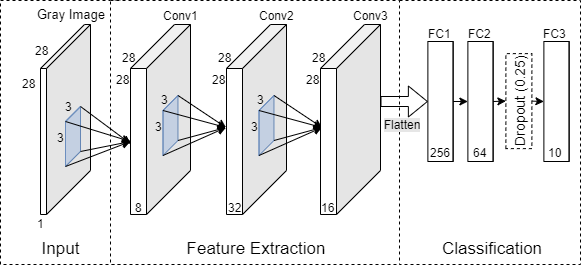

**Fig.1 -** CNN Architecture
